# 6. OCR Awareness — OpenCV

## 6.1 Introduction to OCR

**OCR (Optical Character Recognition)** is the process of converting text present in images into machine-readable text.

Examples:
- Extracting text from scanned documents.
- Reading invoices and receipts.
- Recognizing text on road signs.
- Digitizing printed books.
- Extracting information from forms.

### Why is OCR needed?

Text in an image is represented by pixels. Computers cannot directly treat those pixels as editable characters. OCR analyzes visual patterns and predicts the corresponding letters, numbers, and symbols.

---

## 6.2 Text Regions

### Definition

A **text region** is an area of an image containing text.

Text localization identifies where text is present before or during the recognition process.

### Levels of text localization

1. **Text block:** A paragraph, heading, or table.
2. **Text line:** A horizontal or vertical line of text.
3. **Word:** A group of characters forming a word.
4. **Character:** An individual letter, number, or symbol.

### Example

Consider a receipt containing:

```text
ABC STORES
Chennai

Notebook    Rs. 50
Pen         Rs. 20

Total       Rs. 70
```

An OCR system may locate the heading, individual lines, and table regions before extracting the text.

### How OpenCV helps detect text regions

- **Thresholding:** Separates dark text from a light background.
- **Morphology:** Can join nearby character strokes into text lines.
- **Contours:** Finds boundaries of connected foreground regions.
- **Bounding boxes:** Locates candidate text regions.
- **Connected components:** Identifies connected groups of foreground pixels.

Example:

```python
contours, hierarchy = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )
```

**Limitation:** Contours and connected components do not inherently understand text. They detect geometric regions, which may include letters, punctuation, noise, or non-text objects.

---

## 6.3 OCR Preprocessing

### Definition

**Preprocessing** modifies an image to improve its suitability for text detection and recognition.

The objective is to improve character visibility while preserving important character shapes.

### Common preprocessing operations

| Operation | Purpose |
|---|---|
| Grayscale conversion | Removes unnecessary color information |
| Resizing | Makes small text easier to recognize |
| Denoising | Reduces unwanted speckles and noise |
| Thresholding | Separates text from the background |
| Morphological opening | Removes small foreground noise when appropriate |
| Morphological closing | Can repair small gaps in foreground strokes |
| Deskewing | Corrects tilted text lines |
| Cropping | Removes irrelevant image regions |
| Perspective correction | Rectifies photographed documents taken at an angle |

### Basic preprocessing example

```python
import cv2

image = cv2.imread("document.png")

if image is None:
    raise FileNotFoundError("Could not load document.png")

gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

resized = cv2.resize(
    gray,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

denoised = cv2.GaussianBlur(
    resized,
    (3, 3),
    0
)
```

### Important considerations

- Resizing can help with small text, but excessive enlargement does not recover missing details.
- Gaussian blur reduces noise but can also blur thin character strokes.
- Morphological operations must be selected carefully because they can merge or erase characters.
- Deskewing and perspective correction are different: deskewing corrects rotation, while perspective correction addresses geometric distortion caused by the viewing angle.
- Not every image requires every preprocessing operation.

**Goal:** Improve recognition accuracy without destroying meaningful character details.

---

## 6.4 Thresholding for OCR

### Definition

Thresholding converts a grayscale image into a binary image by comparing pixel intensities against a threshold.

For typical dark text on a light background, binary thresholding can produce black text on a white background.

### A. Global thresholding

A single threshold is applied to the entire image.

```python
_, binary = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)
```

For `cv2.THRESH_BINARY`:

- Pixel value greater than `127` becomes `255` (white).
- Pixel value less than or equal to `127` becomes `0` (black).

**Suitable for:** Images with relatively uniform illumination and strong contrast.

### B. Adaptive thresholding

Adaptive thresholding calculates a local threshold for different image neighborhoods.

```python
binary = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)
```

Parameters:
- `31` — neighborhood block size; must be odd and greater than 1.
- `10` — constant subtracted from the local weighted mean.

**Suitable for:** Documents with uneven illumination, shadows, or varying background brightness.

### C. Otsu's thresholding

Otsu's method automatically selects a global threshold by analyzing the grayscale histogram.

```python
_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
```

The initial threshold argument is ignored when Otsu's method selects the threshold.

**Suitable for:** Images whose foreground and background intensities can be reasonably separated by a global threshold.

### Comparison

| Method | Main advantage | Limitation |
|---|---|---|
| Global thresholding | Simple and fast | Sensitive to uneven lighting |
| Adaptive thresholding | Handles local illumination changes | Depends on neighborhood parameters |
| Otsu's thresholding | Automatically selects a global threshold | Can struggle with uneven lighting or overlapping intensity distributions |

**Common mistake:** Aggressive thresholding can remove thin strokes, break characters, or merge nearby letters. Always inspect the binary result before OCR.

---

## 6.5 Character Recognition Pipeline

### Definition

The OCR pipeline is the sequence of operations used to locate text, recognize its content, and produce machine-readable output.

### Typical workflow

1. **Input image:** Photograph, scan, screenshot, or document.
2. **Preprocessing:** Improve contrast, reduce noise, resize, and correct orientation if needed.
3. **Text detection and layout analysis:** Locate text blocks, lines, words, or other text regions.
4. **Recognition:** Predict the text represented by visual patterns.
5. **Postprocessing:** Optionally correct recognition errors, restore formatting, and structure the output.
6. **Output:** Extracted text or structured information.

### Character segmentation: traditional versus modern OCR

Traditional OCR systems may explicitly segment characters before recognizing them individually.

Modern OCR systems can recognize complete text lines or sequences without separately isolating every character.

Therefore, **character segmentation is not mandatory in every OCR pipeline**.

### OCR implementation using Tesseract

One common option is Tesseract OCR with the Python wrapper `pytesseract`.

Install the Python package:

```bash
pip install pytesseract
```

The Tesseract OCR engine must also be installed separately.

```python
import cv2
import pytesseract

image = cv2.imread("document.png")

if image is None:
    raise FileNotFoundError("Could not load document.png")

gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

text = pytesseract.image_to_string(
    gray,
    lang="eng"
)

print(text)
```

This basic example sends the grayscale image to Tesseract. The engine performs its recognition pipeline and returns extracted text.

Preprocessing, OCR configuration, and language selection can be adjusted for different documents.

### Applications

- Invoice and receipt extraction.
- Document digitization.
- Number plate recognition.
- Form processing.
- Searchable PDF creation.
- Reading text from signs and labels.

---

## 6.6 Common OCR Challenges

1. **Low resolution:** Character strokes may become indistinguishable.
2. **Blur:** Adjacent characters can lose their boundaries.
3. **Uneven lighting:** One global threshold may not separate text consistently.
4. **Skew and perspective:** Text geometry becomes distorted.
5. **Connected characters:** Recognition becomes difficult when letters merge.
6. **Complex layouts:** Tables, columns, and mixed text regions require layout analysis.
7. **Handwriting:** Character shapes vary significantly between writers.
8. **Language and font differences:** Recognition depends on the engine's supported languages and trained models.

## 6.7 Practice Exercises

1. Load a printed invoice and convert it to grayscale.
2. Compare global, adaptive, and Otsu thresholding.
3. Apply resizing and denoising, then compare the images.
4. Detect candidate text regions using contours and bounding boxes.
5. Run Tesseract before and after preprocessing and compare the extracted text.
6. Test OCR on a clean receipt, a rotated document, and a shadowed photograph.
7. Inspect the recognition errors and determine which preprocessing operation helps.

### Final Summary

- **Text regions:** Where is the text?
- **Preprocessing:** How can the image be improved for recognition?
- **Thresholding:** How can foreground text be separated from its background?
- **Character recognition pipeline:** How does an OCR system convert visual text into machine-readable output?

**Key distinction:** OpenCV provides image-processing and localization tools; an OCR engine performs text recognition. Together, they form a practical foundation for document-processing applications.

# 1. Import libraries and verify Tesseract

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

from pathlib import Path

tesseract_path = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

if not tesseract_path.exists():
    raise FileNotFoundError(
        f"Tesseract executable not found: {tesseract_path}"
    )

pytesseract.pytesseract.tesseract_cmd = str(tesseract_path)

print("Tesseract version:", pytesseract.get_tesseract_version())

Tesseract version: 5.5.3.20260724


# 2. Load an image containing text

Image shape: (1696, 1200, 3)
Image dtype: uint8


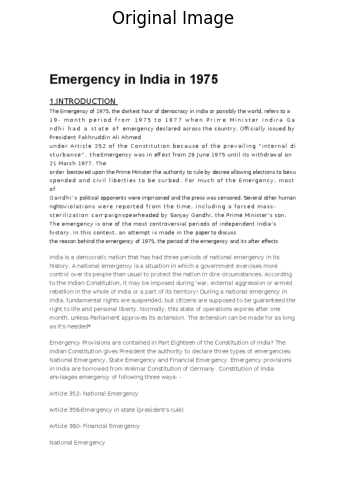

In [3]:
image_path = "images/07_image.png"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

print("Image shape:", image_rgb.shape)
print("Image dtype:", image_rgb.dtype)

plt.figure(figsize=(12, 6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

# 3. Preprocessing

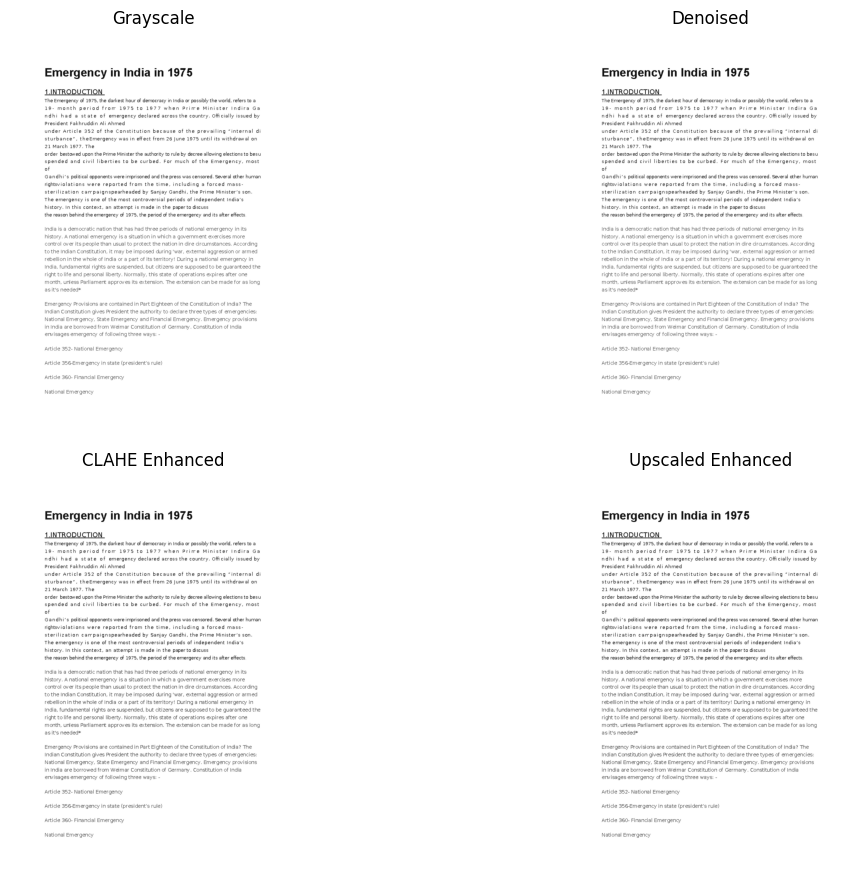

In [4]:
# 1. Grayscale
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# 2. Denoising
denoised = cv2.fastNlMeansDenoising(
    gray,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)

# 3. Contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(denoised)

# 4. Upscale small text for easier inspection and OCR
scale_factor = 2

resized = cv2.resize(
    enhanced,
    None,
    fx=scale_factor,
    fy=scale_factor,
    interpolation=cv2.INTER_CUBIC
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

results = [
    (gray, "Grayscale"),
    (denoised, "Denoised"),
    (enhanced, "CLAHE Enhanced"),
    (resized, "Upscaled Enhanced")
]

for ax, (img, title) in zip(axes.ravel(), results):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 4. Thresholding

Otsu threshold: 176.0


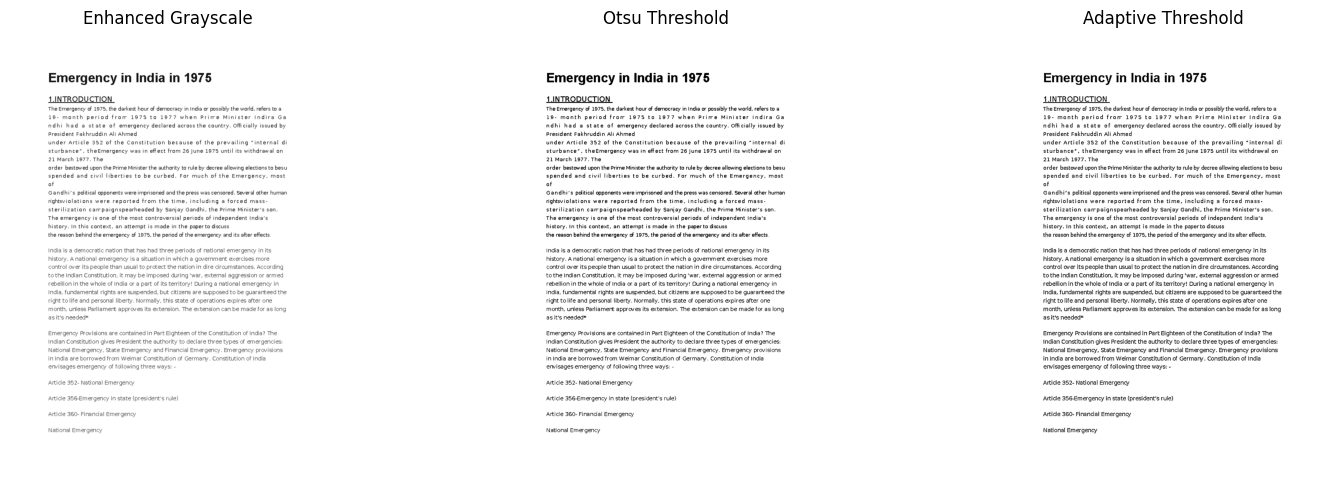

In [5]:
# Otsu thresholding
otsu_threshold, otsu_binary = cv2.threshold(
    resized,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Adaptive Gaussian thresholding
adaptive_binary = cv2.adaptiveThreshold(
    resized,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

print("Otsu threshold:", otsu_threshold)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

threshold_results = [
    (resized, "Enhanced Grayscale"),
    (otsu_binary, "Otsu Threshold"),
    (adaptive_binary, "Adaptive Threshold")
]

for ax, (img, title) in zip(axes, threshold_results):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Text-region detection

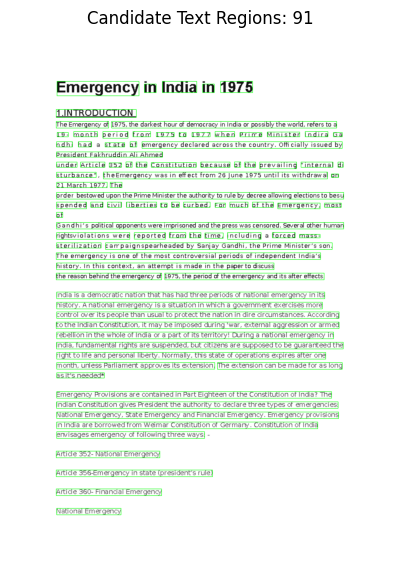

Detected candidate regions: 91


In [6]:
# Convert dark text to white foreground
text_mask = cv2.bitwise_not(otsu_binary)

# Join nearby character strokes horizontally
horizontal_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (25, 3)
)

connected_text = cv2.morphologyEx(
    text_mask,
    cv2.MORPH_CLOSE,
    horizontal_kernel,
    iterations=1
)

contours, _ = cv2.findContours(
    connected_text,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Upscaling changes coordinates, so draw on the upscaled image
region_image = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

text_regions = []

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)

    # Basic filters; tune these to your image
    if w < 20 or h < 8 or area < 30:
        continue

    text_regions.append((x, y, w, h))

    cv2.rectangle(
        region_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(14, 7))
plt.imshow(region_image)
plt.title(f"Candidate Text Regions: {len(text_regions)}")
plt.axis("off")
plt.show()

print("Detected candidate regions:", len(text_regions))

# 6. Character recognition with Tesseract

In [7]:
ocr_inputs = {
    "Grayscale": gray,
    "CLAHE": enhanced,
    "Otsu": otsu_binary,
    "Adaptive": adaptive_binary
}

ocr_results = {}

for method, processed_image in ocr_inputs.items():
    recognized_text = pytesseract.image_to_string(
        processed_image,
        lang="eng",
        config="--psm 6"
    )

    ocr_results[method] = recognized_text

    print(f"\n{'=' * 20} {method} {'=' * 20}")
    print(recognized_text.strip() or "[No text recognized]")


==================== Grayscale ====================
Emergency in India in 1975

INTRODUCTION

The Emergency of 1975, the darkest hour of dernocracy in India or possibly the world, refers to a
19- month period frorr 1975 to 1977 when Prirre Minister Indira Ga
ndhi had a state of emergency declared across the country. Officially issued by
President Fakhruddin Ali Ahmed

under Article 352 of the Constitution because of the prevailing “internal di
sturbance”, theEmergency was in effect from 26 June 1975 until its withdrawal on
21 March 1977. The

order bestowed upon the Prime Minister the authority to rule by decree allowing elections to besu
spended and civil liberties to be curbed. For much of the Emergency, most
of

Gandhi's political opponents were imprisoned and the press was censored. Several other human
rightsviolations were reported from the time, including a forced mass-
sterilization carrpaignspearheaded by Sanjay Gandhi, the Prime Minister’s son.
The emergency is one of the mos

# 7. Extract words, bounding boxes, and confidence

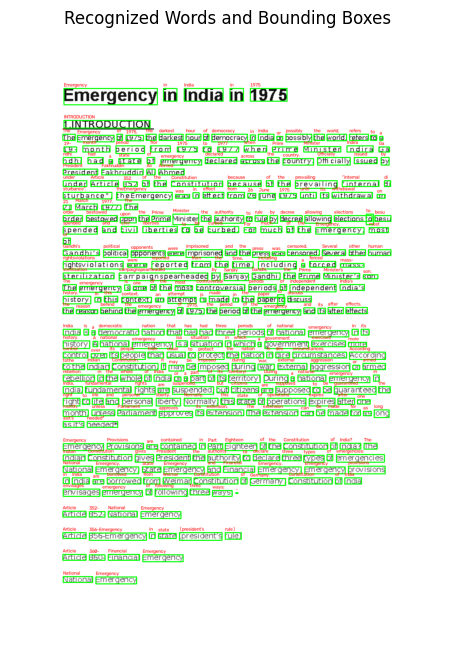

,text,confidence,x,y,width,height
0,Emergency,96.0,148,155,257,45
1,in,95.0,422,155,37,35
2,India,96.0,479,155,107,35
3,in,96.0,605,155,37,35
4,1975,96.0,661,155,101,35
5,INTRODUCTION,43.0,148,243,237,21
6,The,96.0,145,281,34,17
7,Emergency,96.0,185,284,101,18
8,of,96.0,294,281,15,17
9,"1975,",96.0,319,284,48,15


In [8]:
ocr_data = pytesseract.image_to_data(
    enhanced,
    lang="eng",
    config="--psm 6",
    output_type=pytesseract.Output.DICT
)

ocr_visualization = cv2.cvtColor(
    enhanced,
    cv2.COLOR_GRAY2RGB
)

recognized_words = []

for i, word in enumerate(ocr_data["text"]):
    word = word.strip()

    if not word:
        continue

    confidence = float(ocr_data["conf"][i])

    if confidence < 0:
        continue

    x = ocr_data["left"][i]
    y = ocr_data["top"][i]
    w = ocr_data["width"][i]
    h = ocr_data["height"][i]

    recognized_words.append({
        "text": word,
        "confidence": confidence,
        "x": x,
        "y": y,
        "width": w,
        "height": h
    })

    cv2.rectangle(
        ocr_visualization,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        ocr_visualization,
        word[:25],
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(15, 8))
plt.imshow(ocr_visualization)
plt.title("Recognized Words and Bounding Boxes")
plt.axis("off")
plt.show()

words_df = pd.DataFrame(recognized_words)
display(words_df.head(20))